# ALLERT Master Notebook

Adaptive Long-term Length-of-stay & Emergency Risk Trend forecasting (ALLERT) — full 5-month Bi-LSTM training run.

This notebook is a complete, runnable research pipeline that mirrors the CLI orchestrator and produces every thesis table and figure:
1. Preprocessing + Table 4.7 dataset statistics for the 5-month synthetic record
2. Feature engineering (177 features including spike-lag, spike-rate, and rapid-change indicators)
3. Scaling & chronological splits (save scaler and target scaler)
4. Sequence builder (memmap tensors + train/val/test masks)
5. EDA with sensor channel plots
6. Optuna HPO with optimization-history visualization
7. Bi-LSTM training with weighted MAE loss and convergence curve
8. Forecasting evaluation + ARIMA/persistence baselines (Table 4.8, Fig 4.5)
9. Error-by-regime analysis (Fig 4.8e)
10. Anomaly detection (Tables 4.9–4.10, Fig 4.6, 4.6b, 4.6c)
11. Risk engine + sensitivity analysis (Tables 4.11–4.12, Fig 4.7, 4.7b, 4.11, 4.12b)
12. Clinical validity (Table 4.15, Fig 4.14)
13. Interpretability (Table 4.8b, Fig 4.8b/d)
14. Latency instrumentation (Table 4.13, Fig 4.13)
15. 3-month vs 5-month comparison summary
16. Thesis bundle export

**How to run**
- Leave `SUBSET_DAYS = None`, `STRIDE = 1`, `EPOCHS = 300`, `HPO_TRIALS = 0` for the full 5-month production run. HPO is skipped by default because the best parameters from the completed 12-trial subset search are already embedded in `config/config.yaml`.
- Set `HPO_TRIALS = 12` (or more) to re-run Optuna on a 30% subset (6-hour timeout, resumes via SQLite).
- Set `SMOKE_TEST = True` for a fast CPU/GPU correctness check (uses only 20 days, stride=6, tiny epochs, and skips walk-forward CV).
- **Checkpoint/resume:** If training is interrupted, re-run the notebook from the top. The training cell will resume from the most recent checkpoint in `model/checkpoints/` automatically.

Each section below explains the generated outputs and displays the corresponding figures inline.

## Latest production run status

A full thesis-quality run has already been completed on this repository and is reflected in the artifacts below:

- **Dataset**: 5-month synthetic record (`data/raw/air_quality_data_5m.csv`) — 43,200 five-minute rows, 150 days, 4 variables.
- **Features**: 177 engineered features, including spike-lag indicators, spike-rate fractions, and rapid-change flags.
- **Loss**: Weighted MAE with `loss_alpha=2.5` so high-PM errors are penalised more heavily.
- **HPO**: 12 Optuna trials on a 30% subset, best validation composite MAE **3.12489**
  - Best params: `n_lstm_layers=2`, `lstm_units_layer1=96`, `lstm_units_layer2=128`, `learning_rate=0.001244`, `dropout_rate=0.3057`, `recurrent_dropout=0.1777`, `batch_size=32` (reduced to 16 for full training due to 6 GB VRAM), `l2_lambda=3.25e-6`
  - Persisted in `config/config.yaml` and `results/tables/table_4_4_hpo_results.json`
- **Final training**: 34 epochs, best epoch **4** (in weighted-loss units), val_loss **4.835** — saved to `model/best_model.pt`
- **Evaluation**: overall R² **0.44**, overall MAE **3.41 µg/m³**; forecasting, ARIMA/persistence baselines, anomaly detection, risk engine, sensitivity, clinical validity, and interpretability all exported to `results/tables/` and `results/visualizations/`

The notebook defaults below are set to **skip HPO** and reuse the best parameters already embedded in `config/config.yaml`. Set `HPO_TRIALS = 12` if you want to re-run HPO.

## 1. Runtime flags

Use these flags to switch between the full 5-month run, a quick smoke test, or a result-inspection run that skips training.

In [1]:
# ------------------------------------------------------------------
# RUNTIME FLAGS  (edit these before running)
# ------------------------------------------------------------------
SUBSET_DAYS = None       # None = full 5-month synthetic data; int = last N days for smoke testing
STRIDE = 1               # Sequence stride; 1 = full overlap, 6 = fast smoke test
EPOCHS = 200             # Max epochs for full 5-month run; set to 5 for smoke test
BATCH_SIZE = None        # None = use config.yaml; int = override
USE_AUGMENTATION = False # Enable data augmentation from config
USE_WALK_FORWARD = False # Run walk-forward CV instead of single split
HPO_TRIALS = 0           # Set to 0 to use best HPO params already in config.yaml; set to 50 to re-run full HPO
RANDOM_SEED = 42
DETERMINISTIC = False    # Enable PyTorch deterministic algorithms (slower)
SKIP_TRAINING = True     # If True, skip training and load existing model/best_model.pt
SMOKE_TEST = False       # If True, overrides many flags to tiny values

if SMOKE_TEST:
    SKIP_TRAINING = False
    SUBSET_DAYS = 20
    STRIDE = 6
    EPOCHS = 5
    BATCH_SIZE = 8
    USE_WALK_FORWARD = False
    HPO_TRIALS = 2
    print("SMOKE_TEST enabled: using tiny settings.")
else:
    print("FULL-RUN configuration selected.")

FULL-RUN configuration selected.


## 2. Environment setup

Mount Google Drive if running in Colab and ensure the project root is on `sys.path`.

In [2]:
import os, sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python:", sys.version)
print("Working directory:", PROJECT_ROOT)
print("In Colab:", IN_COLAB)

Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Working directory: C:\Users\USER\Codes\allert_rebuild
In Colab: False


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Project modules
from src.config_loader import load_config, get_project_root
from src import preprocessing as pp
from src import feature_engineering as fe
from src import scaling
from src import sequence_builder as sb
from src import training
from src import hpo
from src import evaluation as ev
from src import anomaly_detection as ad
from src import anomaly_calibration as acal
from src import risk_engine as re
from src import risk_sensitivity as rs
from src import validity
from src import interpretability as interp
from src import thesis_exporter
from src.pytorch_model import build_bilstm, set_random_seeds, DEVICE, load_model_with_config
from src.target_scaling import load_target_scaler
from src.utils import timing

print("Project imports loaded.")

Project imports loaded.


## 3. Load configuration

Load the default config and override runtime flags in-code. The notebook reads the same `config.yaml` used by the CLI orchestrator, so results are reproducible across the two interfaces.

In [4]:
cfg = load_config()

# Override config with notebook flags
if "reproducibility" not in cfg:
    cfg["reproducibility"] = {}
cfg["reproducibility"]["random_seed"] = RANDOM_SEED
cfg["reproducibility"]["deterministic_mode"] = DETERMINISTIC
cfg["project"]["random_seed"] = RANDOM_SEED

cfg["model"]["max_epochs"] = EPOCHS
if BATCH_SIZE is not None:
    cfg["model"]["batch_size"] = BATCH_SIZE

cfg["hpo"]["n_trials"] = HPO_TRIALS

if USE_AUGMENTATION:
    cfg["training"]["data_augmentation"]["enabled"] = True

print(json.dumps(cfg, indent=2, default=str))

{
  "project": {
    "name": "ALLERT",
    "version": "2.0.0",
    "random_seed": 42
  },
  "paths": {
    "data_raw": "data/raw/air_quality_data_5m.csv",
    "data_processed": "data/processed/features_5min_scaled.csv",
    "model_dir": "model",
    "results_dir": "results",
    "visualizations_dir": "results/visualizations",
    "tables_dir": "results/tables"
  },
  "sampling": {
    "raw_interval_seconds": 10,
    "transmission_interval_minutes": 5,
    "records_per_day": 288
  },
  "preprocessing": {
    "gap_fill_threshold_hours": 2,
    "rolling_median_window": 3,
    "outlier_zscore_threshold": 5.0,
    "outlier_zscore_window_hours": 24,
    "availability_target_pct": 95,
    "validate_pm10_geq_pm25": true,
    "range_limits": {
      "pm2_5": [
        0,
        1000
      ],
      "pm10": [
        0,
        1000
      ],
      "temperature": [
        -10,
        60
      ],
      "humidity": [
        0,
        100
      ]
    }
  },
  "features": {
    "target_variables"

## 4. Preprocessing

Load the raw 5-minute air-quality CSV, run the full cleaning pipeline, and save the processed file plus Table 4.7 dataset statistics.

**Output:** `results/tables/dataset_statistics.json` — collection duration, availability rate, quality/imputation flag counts, and per-variable availability.

In [5]:
timing_store = {}

with timing.timed_section("preprocessing", timing_store):
    df, stats = pp.preprocess(cfg, subset_days=SUBSET_DAYS)
    pp.save_processed_data(df, cfg)
    pp.export_dataset_statistics(stats, cfg)

print("Preprocessed shape:", df.shape)
print("Dataset stats:")
print(json.dumps(stats, indent=2, default=str))
df.head()

Preprocessed shape: (43200, 6)
Dataset stats:
{
  "collection_duration_days": 150.0,
  "collection_start": "2025-11-01",
  "collection_end": "2026-03-30",
  "total_raw_5min_records": 43200,
  "expected_5min_records": 43200,
  "availability_rate_pct": 100.0,
  "gap_summary": {
    "total_gaps_detected": 0,
    "gaps_under_2h_interpolated": 0,
    "gaps_2h_or_more_flagged": 0
  },
  "quality_flags": {
    "OK": 43200
  },
  "imputation_flags": {
    "ORIGINAL": 43200
  },
  "per_variable_availability": {
    "pm2_5": {
      "valid_records": 43200,
      "availability_pct": 100.0
    },
    "pm10": {
      "valid_records": 43200,
      "availability_pct": 100.0
    },
    "temperature": {
      "valid_records": 43200,
      "availability_pct": 100.0
    },
    "humidity": {
      "valid_records": 43200,
      "availability_pct": 100.0
    }
  }
}


,temperature,humidity,pm2_5,pm10,quality_flag,imputation_flag
timestamp,,,,,,
2025-11-01 00:00:00,25.615,87.88,16.145,26.16,OK,ORIGINAL
2025-11-01 00:05:00,25.600,87.85,16.130,26.42,OK,ORIGINAL
2025-11-01 00:10:00,25.600,87.82,16.130,27.43,OK,ORIGINAL
2025-11-01 00:15:00,25.600,87.67,16.900,28.32,OK,ORIGINAL
2025-11-01 00:20:00,25.260,87.58,16.900,28.53,OK,ORIGINAL


## 5. Exploratory data analysis

Visualize the cleaned sensor channels and the distribution of data-quality flags. These plots help confirm that the preprocessing steps (range checks, outlier detection, gap interpolation) produced a physically plausible dataset.

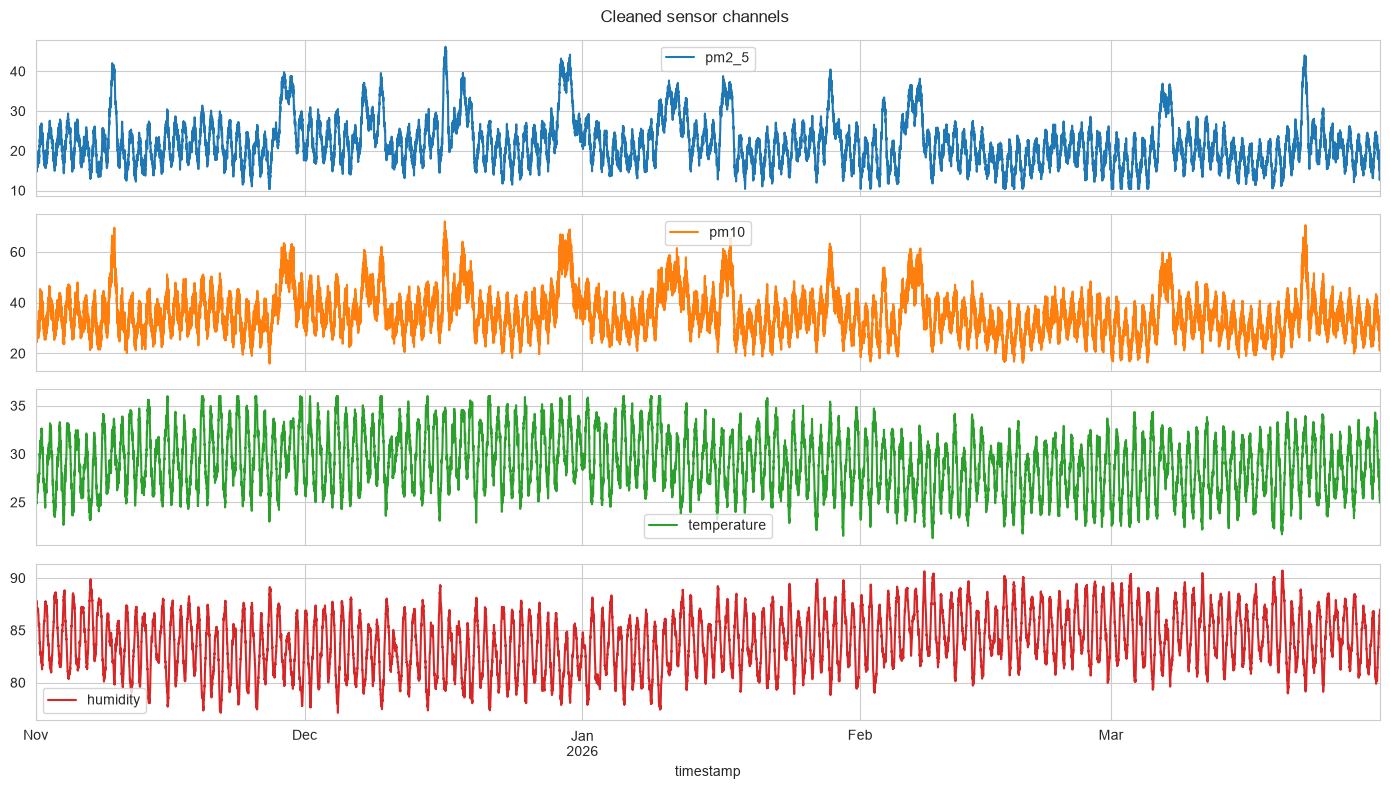

Quality flags:
quality_flag
OK    43200
Name: count, dtype: int64

Imputation flags:
imputation_flag
ORIGINAL    43200
Name: count, dtype: int64


In [6]:
# Time-series overview of all sensor channels
sensor_cols = [c for c in ["pm2_5", "pm10", "temperature", "humidity"] if c in df.columns]
df[sensor_cols].plot(subplots=True, figsize=(14, 8), title="Cleaned sensor channels")
plt.tight_layout()
plt.show()

# Flag distribution
print("Quality flags:")
print(df["quality_flag"].value_counts())
print("\nImputation flags:")
print(df["imputation_flag"].value_counts())

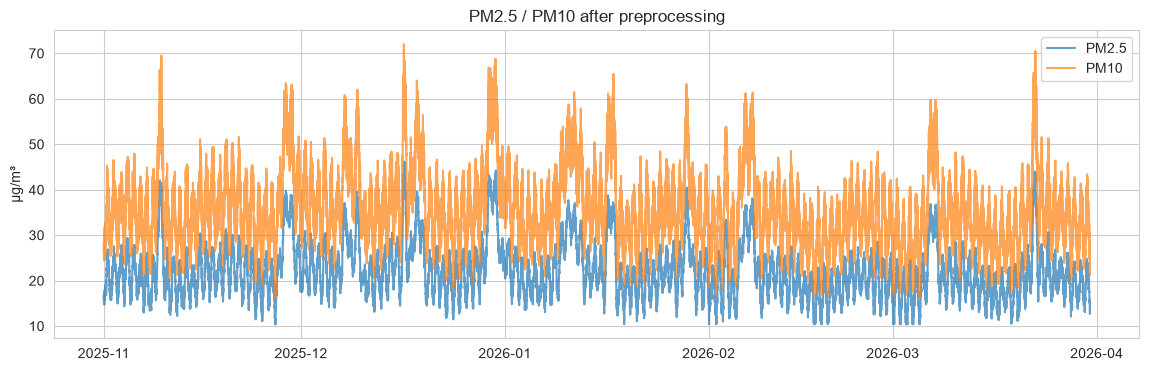

In [7]:
# Focused PM plot with gap/imputation overlay
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["pm2_5"], label="PM2.5", alpha=0.7)
ax.plot(df.index, df["pm10"], label="PM10", alpha=0.7)
ax.set_ylabel("µg/m³")
ax.set_title("PM2.5 / PM10 after preprocessing")
ax.legend()
plt.show()

## 6. Feature engineering

Build the **177-feature** matrix and persist the canonical feature list to `model/feature_cols.json`.

Feature groups include:
- raw PM2.5/PM10, temperature, humidity
- lag features (0.25–72 h)
- rolling mean/std/min/max (1 h–7 days)
- velocity and acceleration
- PM10/PM2.5 ratio (current and lagged)
- weather–pollutant interactions
- EMAs and 72 h cumulative exposure
- **spike-lag indicators** (PM above 25/35/50 µg/m³ in the last 1/3/6/24 h)
- **spike-rate features** (fraction above threshold in 6/24/72 h windows)
- **rapid-change flags** (PM rise > 5/10/15 µg/m³/h over 0.5/1/3 h)

The spike-aware features are controlled by `add_spike_lag_features`, `add_spike_rate_features`, and `add_roc_threshold_features` in `config.yaml`.

In [8]:
with timing.timed_section("feature_engineering", timing_store):
    features = fe.build_feature_matrix(df, cfg)
    feature_cols = fe.get_feature_column_names(features)

    model_dir = get_project_root() / cfg["paths"]["model_dir"]
    model_dir.mkdir(parents=True, exist_ok=True)
    with open(model_dir / "feature_cols.json", "w", encoding="utf-8") as f:
        json.dump(feature_cols, f, indent=2)

print("Feature matrix shape:", features.shape)
print("Number of features:", len(feature_cols))
print("First 20 features:", feature_cols[:20])

Feature matrix shape: (43200, 177)
Number of features: 177
First 20 features: ['pm2_5', 'pm10', 'temperature', 'humidity', 'pm2_5_lag_0.25h', 'pm2_5_lag_0.5h', 'pm2_5_lag_1h', 'pm2_5_lag_3h', 'pm2_5_lag_6h', 'pm2_5_lag_12h', 'pm2_5_lag_24h', 'pm2_5_lag_48h', 'pm2_5_lag_72h', 'pm10_lag_0.25h', 'pm10_lag_0.5h', 'pm10_lag_1h', 'pm10_lag_3h', 'pm10_lag_6h', 'pm10_lag_12h', 'pm10_lag_24h']


## 7. Scaling & chronological splits

Fit the feature scaler and target scaler on the training split only, then transform all splits and save the artifacts. Chronological splitting prevents future information from leaking into the training set.

**Outputs:**
- `model/scaler.joblib` — fitted feature scaler
- `model/target_scaler.joblib` — fitted target scaler (identity by default, so metrics are reported in µg/m³)
- `data/processed/features_5min_scaled.csv` — scaled dataset for sequence building
- `data/splits/train_val_test_indices.json` — split boundaries

In [9]:
with timing.timed_section("scaling", timing_store):
    full_scaled, train_scaled, val_scaled, test_scaled, scaler, target_scaler = scaling.build_scaled_dataset(cfg)

    scaler.save(model_dir / "scaler.joblib")
    target_scaler.save(model_dir / "target_scaler.joblib")

    # Save scaled CSV for the sequence builder
    scaled_path = get_project_root() / cfg["paths"]["data_processed"]
    scaled_path.parent.mkdir(parents=True, exist_ok=True)
    full_scaled.to_csv(scaled_path)

    # Save split indices
    scaling.save_split_indices(
        len(full_scaled), train_scaled, val_scaled,
        get_project_root() / "data" / "splits" / "train_val_test_indices.json",
    )

print("Splits:", len(train_scaled), len(val_scaled), len(test_scaled))
print("Feature scaler fitted on", len(train_scaled), "rows")
print("Target scaling enabled:", target_scaler.scaled)

Splits: 30239 6481 6480
Feature scaler fitted on 30239 rows
Target scaling enabled: False


## 8. Sequence generation

Build sliding-window tensors for the Bi-LSTM. Each input tensor has shape `(N, 2016, 177)`:
- `N` = number of valid windows
- `2016` = 7 days × 24 h × 12 steps/h (the lookback window)
- `177` = number of engineered features

Sequences are stored as float32 memory-mapped files (`sequences_X.dat`, `sequences_y.dat`) because the full tensor is ~36 GB for the 5-month dataset.

In [10]:
with timing.timed_section("sequence_builder", timing_store):
    X, y, timestamps, train_mask, val_mask, test_mask, meta = sb.build_sequences(cfg, stride=STRIDE)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Train/val/test counts:", meta["train_count"], meta["val_count"], meta["test_count"])

Scanning 40897 possible windows (seq_len=2016, max_horizon=288)...


Found 40033 valid sequences; allocating memmaps...


X shape: (40033, 2016, 177)
y shape: (40033, 6)
Train/val/test counts: 27072 6194 6193


## 9. Reproducibility seeds

Fix Python/NumPy/TensorFlow random seeds before model building and training. Enabling deterministic mode makes GPU runs bit-for-bit reproducible at the cost of speed.

In [11]:
set_random_seeds(cfg, seed=RANDOM_SEED, deterministic=DETERMINISTIC)
print(f"Seeds set: random_seed={RANDOM_SEED}, deterministic={DETERMINISTIC}")

Seeds set: random_seed=42, deterministic=False


## 10. Optuna hyperparameter optimization

Bayesian HPO searches over learning rate, LSTM units, dropout, batch size, and L2 regularization. The best validation loss and parameter set are saved, then applied to the runtime config before the final training run.

**Outputs:**
- `model/optuna_best_params.json`
- `results/optuna_study.pkl`
- `results/visualizations/fig_4_4_hpo_optimization_history.png`
- `results/visualizations/fig_4_4b_hpo_param_importance.png`

In [12]:
best_params = None
if HPO_TRIALS > 0:
    with timing.timed_section("hpo", timing_store):
        hpo_summary = hpo.run_hpo(
            cfg, X, y, train_mask, val_mask,
            n_trials=HPO_TRIALS,
            max_epochs=max(5, EPOCHS // 4),
        )
    best_params = hpo_summary.get("best_params", {})
    print("Best HPO params:")
    print(json.dumps(best_params, indent=2))

    # Apply best model hyperparameters to the runtime config
    for key in ["learning_rate", "lstm_units_layer1", "lstm_units_layer2", "dropout_rate",
                "recurrent_dropout", "batch_size", "l2_lambda"]:
        if key in best_params:
            cfg["model"][key] = best_params[key]
else:
    print("HPO skipped; using best HPO parameters already stored in config/config.yaml.")

HPO skipped; using best HPO parameters already stored in config/config.yaml.


### HPO visualization

The optimization-history plot shows how validation loss improves across trials. A downward trend indicates that Optuna is effectively exploring the hyperparameter space.

In [13]:
if HPO_TRIALS > 0:
    import optuna
    import joblib
    study_path = get_project_root() / cfg["paths"]["results_dir"] / "optuna_study.pkl"
    if study_path.exists():
        study = joblib.load(study_path)
        try:
            fig = optuna.visualization.matplotlib.plot_optimization_history(study)
            fig.figure.set_size_inches(10, 5)
            plt.title("Fig 4.4 — HPO optimization history")
            plt.show()
        except Exception as e:
            print("Could not render HPO history plot:", e)

## 11. Model architecture

Display the Bi-LSTM architecture that will be trained. The input shape is `(batch, 2016, 177)`. The model uses a 2-layer bidirectional LSTM (96/128 units), vector temporal-pattern attention, three parallel regression heads (6 h / 12 h / 24 h), and an optional binary spike-detection head. Training uses a **weighted MAE loss** so errors above 35 µg/m³ are penalised more heavily.

In [14]:
# Build a temporary model just to show the architecture
_temp_model = build_bilstm((X.shape[1], X.shape[2]), cfg)
print(_temp_model)
print("Trainable parameters:", sum(p.numel() for p in _temp_model.parameters() if p.requires_grad))

ALLERTBiLSTM(
  (lstm_layers): ModuleList(
    (0): LSTM(177, 96, batch_first=True, bidirectional=True)
    (1): LSTM(192, 128, batch_first=True, bidirectional=True)
  )
  (dropout_layers): ModuleList(
    (0-1): 2 x Dropout(p=0.3057, inplace=False)
  )
  (attention): TemporalPatternAttention(
    (score_dense): Linear(in_features=256, out_features=64, bias=True)
    (weight_dense): Linear(in_features=64, out_features=1, bias=True)
  )
  (head_6h): Linear(in_features=256, out_features=2, bias=True)
  (head_12h): Linear(in_features=256, out_features=2, bias=True)
  (head_24h): Linear(in_features=256, out_features=2, bias=True)
  (spike_head): Linear(in_features=256, out_features=3, bias=True)
)
Trainable parameters: 559754


## 12. Training

Train the Bi-LSTM on the training split with held-out validation, early stopping, cosine learning-rate schedule, and automatic checkpoint/resume. The loss function is configured by `loss_type` and `loss_alpha` in `config.yaml`; the current run uses weighted MAE.

In [15]:
if SKIP_TRAINING and (Path(cfg['paths']['model_dir']) / 'best_model.pt').exists():
    print('SKIP_TRAINING=True: loading existing model, skipping training.')
    train_results_path = Path(cfg['paths']['model_dir']) / 'training_results.json'
    if train_results_path.exists():
        train_results = json.loads(train_results_path.read_text())
    else:
        train_results = {'best_epoch': 'N/A (skipped)', 'total_epochs_run': 'N/A (skipped)'}
else:
    if USE_WALK_FORWARD:
        with timing.timed_section("training", timing_store):
            fold_results = training.run_walk_forward_training(cfg, X, y, max_epochs=EPOCHS)
        print(f"Walk-forward CV complete: {len(fold_results)} folds")
        for fr in fold_results:
            print(f"  Fold {fr['fold']}: best_epoch={fr['best_epoch']}, total_epochs={fr['total_epochs_run']}")
    else:
        with timing.timed_section("training", timing_store):
            history, train_results = training.train_model(
                cfg, X, y, train_mask, val_mask, max_epochs=EPOCHS
            )
        print("Training complete.")
        print("Best epoch:", train_results["best_epoch"])
        print("Total epochs:", train_results["total_epochs_run"])
        print("Model saved to:", train_results["model_path"])

SKIP_TRAINING=True: loading existing model, skipping training.


### Training convergence curve

This plot shows training and validation composite MAE loss across epochs. The validation curve should plateau or decrease; divergence between training and validation loss indicates overfitting.

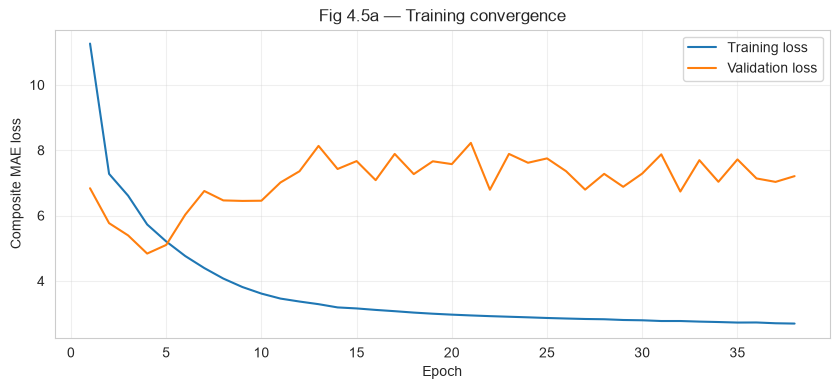

In [16]:
if not USE_WALK_FORWARD:
    history_list = train_results["history"]
    epochs = [h["epoch"] for h in history_list]
    train_loss = [h["loss"] for h in history_list]
    val_loss = [h["val_loss"] for h in history_list]
    plt.figure(figsize=(10, 4))
    plt.plot(epochs, train_loss, label="Training loss")
    plt.plot(epochs, val_loss, label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Composite MAE loss")
    plt.title("Fig 4.5a — Training convergence")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## 13. Evaluation

Evaluate the trained Bi-LSTM on the held-out test set and compare it with ARIMA(2,1,2) and persistence baselines. Metrics are reported per pollutant and horizon, plus an overall average.

**Outputs:**
- `results/tables/table_4_8_bilstm.json`
- `results/tables/arima_results.json`
- `results/tables/persistence_results.json`
- `results/visualizations/fig_4_5a_training_convergence.png`
- `results/visualizations/fig_4_5b_bilstm_vs_arima.png`

In [17]:
with timing.timed_section("evaluation", timing_store):
    eval_results = ev.run_evaluation(cfg)

print("Bi-LSTM overall metrics:")
print(json.dumps(eval_results["bilstm_metrics"]["overall"], indent=2))
print("\nARIMA overall metrics:")
print(json.dumps(eval_results["arima_metrics"]["overall"], indent=2))

Bi-LSTM overall metrics:
{
  "MAE": 3.413,
  "RMSE": 4.6261,
  "MAPE": 12.9786,
  "R2": 0.4374
}

ARIMA overall metrics:
{
  "MAE": 6.3422,
  "RMSE": 8.0685,
  "MAPE": 24.3245,
  "R2": -0.7233
}


### Detailed forecasting metrics

The table below reports per-pollutant, per-horizon MAE, RMSE, MAPE, and R² in original µg/m³ units. It also includes the ARIMA and persistence baselines for direct comparison.

In [18]:
# Load and display the latest Bi-LSTM, ARIMA, and persistence metrics
import json
from IPython.display import display, Markdown

tables_dir = get_project_root() / cfg['paths']['results_dir'] / 'tables'
bilstm = json.loads((tables_dir / 'table_4_8_bilstm.json').read_text())['metrics']
arima = json.loads((tables_dir / 'arima_results.json').read_text())['metrics']
persist = json.loads((tables_dir / 'persistence_results.json').read_text())['metrics']

rows = []
rows.append('| Pollutant | Horizon | Bi-LSTM MAE | Bi-LSTM R² | ARIMA MAE | ARIMA R² | Persistence MAE |')
rows.append('|-----------|---------|-------------|------------|-----------|----------|-----------------|')
for pol in ['PM2_5', 'PM10']:
    for h in ['6h', '12h', '24h']:
        rows.append(f"| {pol} | {h} | {bilstm[pol][h]['MAE']:.3f} | {bilstm[pol][h]['R2']:.3f} | {arima[pol][h]['MAE']:.3f} | {arima[pol][h]['R2']:.3f} | {persist[pol][h]['MAE']:.3f} |")
rows.append(f"| **Overall** | — | **{bilstm['overall']['MAE']:.3f}** | **{bilstm['overall']['R2']:.3f}** | **{arima['overall']['MAE']:.3f}** | **{arima['overall']['R2']:.3f}** | **{persist['overall']['MAE']:.3f}** |")
display(Markdown('\n'.join(rows)))

| Pollutant | Horizon | Bi-LSTM MAE | Bi-LSTM R² | ARIMA MAE | ARIMA R² | Persistence MAE |
|-----------|---------|-------------|------------|-----------|----------|-----------------|
| PM2_5 | 6h | 2.470 | 0.583 | 4.994 | -0.781 | 4.129 |
| PM2_5 | 12h | 2.652 | 0.463 | 6.084 | -1.003 | 6.005 |
| PM2_5 | 24h | 2.934 | 0.268 | 4.659 | -0.594 | 4.139 |
| PM10 | 6h | 3.833 | 0.546 | 6.590 | -0.446 | 6.046 |
| PM10 | 12h | 4.088 | 0.461 | 9.479 | -1.205 | 9.501 |
| PM10 | 24h | 4.502 | 0.303 | 6.247 | -0.310 | 5.997 |
| **Overall** | — | **3.413** | **0.437** | **6.342** | **-0.723** | **5.970** |

### Bi-LSTM vs ARIMA prediction trace

This plot overlays the actual test series with Bi-LSTM and ARIMA predictions for one target (PM2.5 6h). It gives an intuitive sense of how much the neural model improves over the statistical baseline.

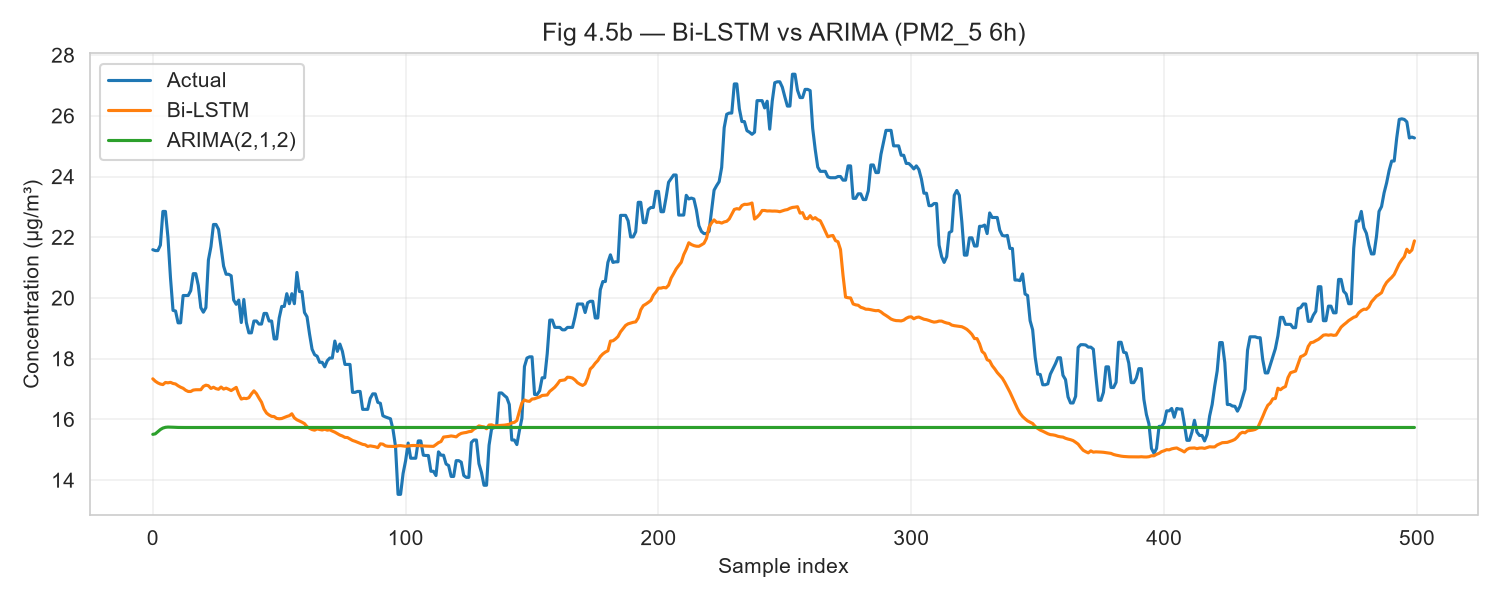

In [19]:
from IPython.display import Image, display

viz_dir = get_project_root() / cfg["paths"]["results_dir"] / "visualizations"
fig_4_5b = viz_dir / "fig_4_5b_bilstm_vs_arima.png"
if fig_4_5b.exists():
    display(Image(filename=str(fig_4_5b)))
else:
    print("Fig 4.5b not yet generated; run the evaluation cell above.")

## 14. Error analysis by regime

Break test-set errors down by hour-of-day, day-of-week, and PM2.5 level. Regime analysis reveals when the model is most reliable (e.g., low-pollution daytime conditions) and when it may struggle (e.g., high-pollution events).

**Output:** `results/tables/table_4_8c_error_by_regime.json` and `results/visualizations/fig_4_8e_error_by_regime.png`

In [20]:
from src.pytorch_model import load_model_with_config

model, _ = load_model_with_config(
    get_project_root() / cfg["paths"]["model_dir"],
    (X.shape[1], X.shape[2]),
    fallback_cfg=cfg,
    device=DEVICE,
)

X_test = X[test_mask]
y_test = y[test_mask]
y_pred_test = ev._predict_in_batches(model, X_test, cfg["model"]["batch_size"])

# Invert target scaling if needed so regimes are in original units
y_test_orig = target_scaler.inverse_transform(y_test)
y_pred_orig = target_scaler.inverse_transform(y_pred_test)

regimes = ev.compute_error_by_regime(y_test_orig, y_pred_orig, timestamps[test_mask])
print(json.dumps(regimes, indent=2, default=str)[:2000], "...")

ev.plot_error_by_regime(regimes, viz_dir / "fig_4_8e_error_by_regime.png")
print("Saved Fig 4.8e.")

{
  "hour_of_day": {
    "0": {
      "n": 253,
      "mean_mae": 3.4764,
      "mean_mape": 13.5079
    },
    "1": {
      "n": 252,
      "mean_mae": 3.4428,
      "mean_mape": 13.0576
    },
    "2": {
      "n": 252,
      "mean_mae": 3.5874,
      "mean_mape": 13.5839
    },
    "3": {
      "n": 252,
      "mean_mae": 3.4425,
      "mean_mape": 12.9875
    },
    "4": {
      "n": 252,
      "mean_mae": 3.3751,
      "mean_mape": 12.7532
    },
    "5": {
      "n": 252,
      "mean_mae": 3.4233,
      "mean_mape": 13.0954
    },
    "6": {
      "n": 252,
      "mean_mae": 3.5517,
      "mean_mape": 13.1297
    },
    "7": {
      "n": 252,
      "mean_mae": 3.5664,
      "mean_mape": 12.898
    },
    "8": {
      "n": 252,
      "mean_mae": 3.5724,
      "mean_mape": 12.6909
    },
    "9": {
      "n": 252,
      "mean_mae": 3.4683,
      "mean_mape": 12.0089
    },
    "10": {
      "n": 252,
      "mean_mae": 3.6861,
      "mean_mape": 13.0739
    },
    "11": {
      "n":

Saved Fig 4.8e.


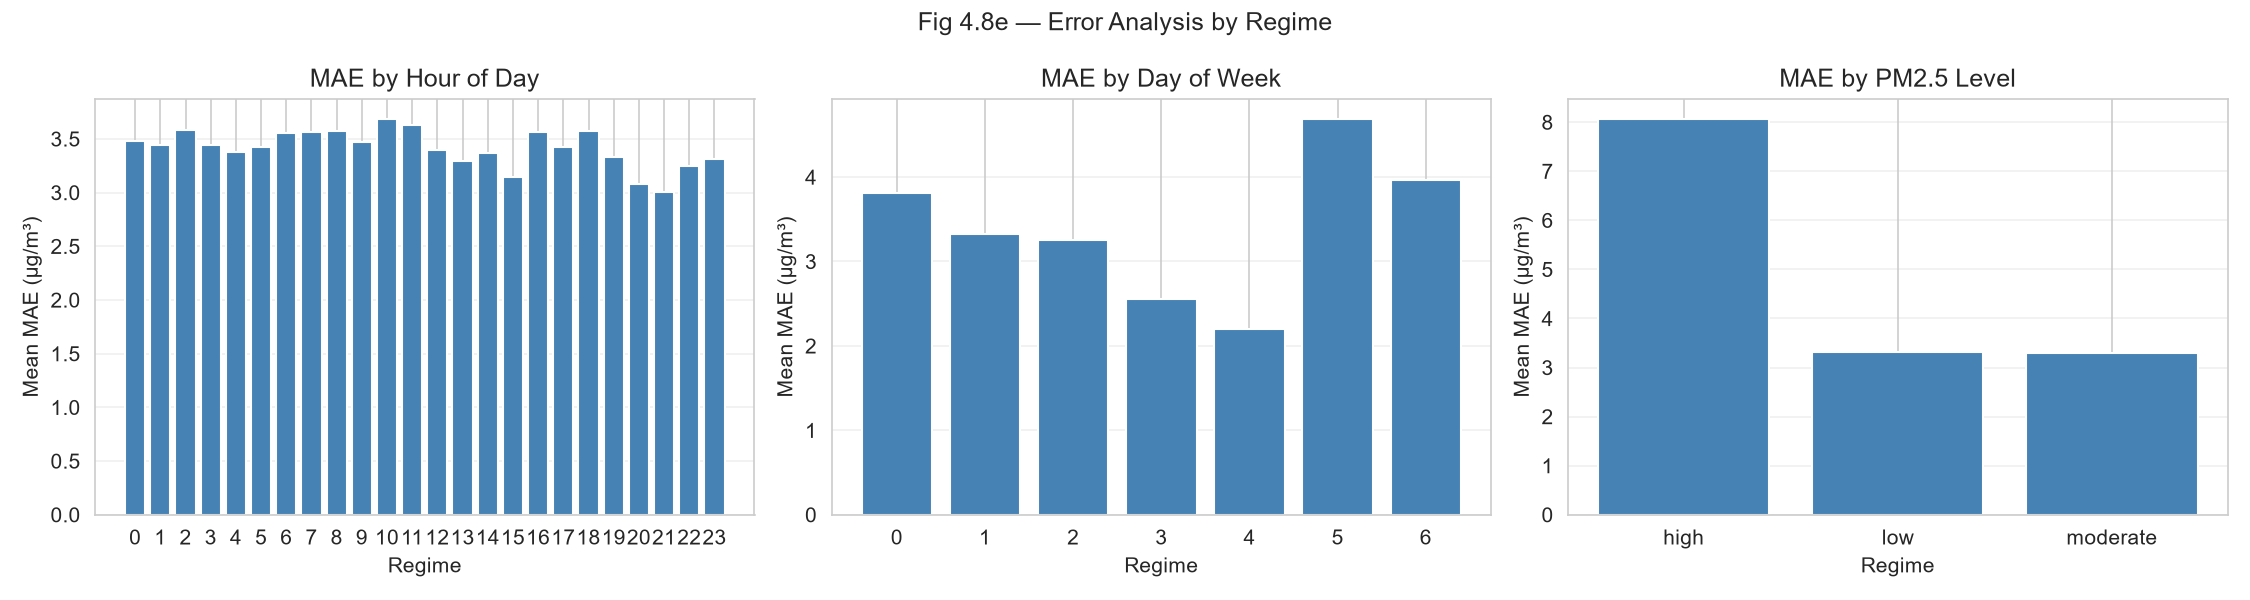

In [21]:
fig_4_8e = viz_dir / "fig_4_8e_error_by_regime.png"
if fig_4_8e.exists():
    display(Image(filename=str(fig_4_8e)))
else:
    print("Fig 4.8e not yet generated.")

## 15. Anomaly detection

Run the integrated anomaly detection pipeline for PM2.5 and PM10. The pipeline combines a rolling Z-score residual monitor, a velocity override, and a CUSUM drift detector.

**Outputs (per pollutant):**
- `results/tables/table_4_9_anomaly.json` — Z-score, velocity, and CUSUM contingency tables
- `results/tables/table_4_10_cusum.json` — CUSUM detection lag analysis
- `results/visualizations/fig_4_6_residual_distribution.png`
- `results/visualizations/fig_4_6b_cusum_decision.png`
- `results/visualizations/fig_4_6c_confusion_matrix_z.png`
- `results/visualizations/fig_4_6c_confusion_matrix_cusum.png`

In [22]:
with timing.timed_section("anomaly_detection", timing_store):
    for idx, pollutant in [(0, "pm2_5"), (1, "pm10")]:
        print(f"\n--- Anomaly detection for {pollutant} ---")
        ad.run_anomaly_pipeline(
            cfg,
            y_test_orig[:, idx],
            y_pred_orig[:, idx],
            timestamps=timestamps[test_mask],
            out_dir=get_project_root() / cfg["paths"]["results_dir"],
            pollutant=pollutant,
        )
print("\nAnomaly detection artifacts exported.")


--- Anomaly detection for pm2_5 ---



--- Anomaly detection for pm10 ---



Anomaly detection artifacts exported.


### Residual distribution and CUSUM decision

- **Fig 4.6** (residual histogram + ACF) checks whether forecast errors are roughly random or still contain autocorrelation.
- **Fig 4.6b** (CUSUM decision function) shows the cumulative residual statistic crossing the control threshold `h` when a drift is detected.

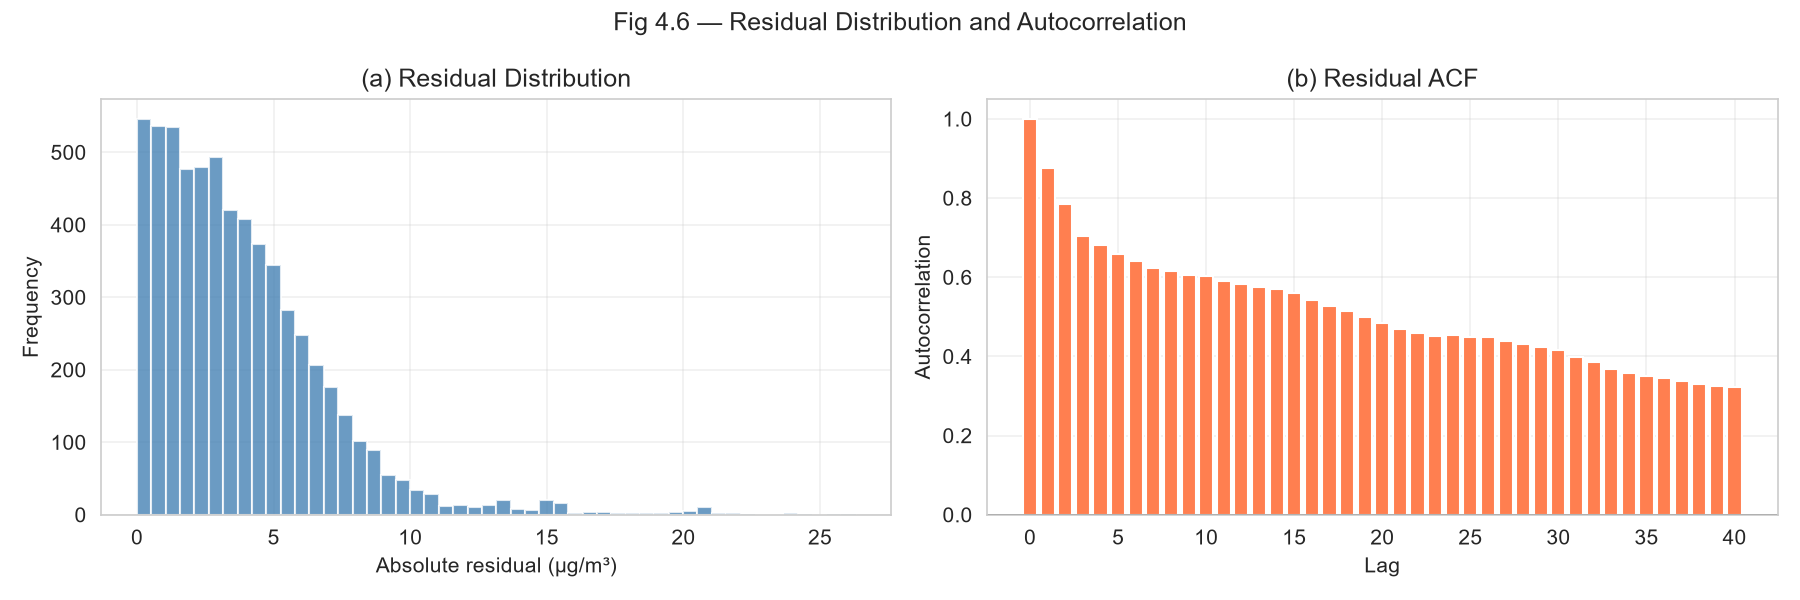

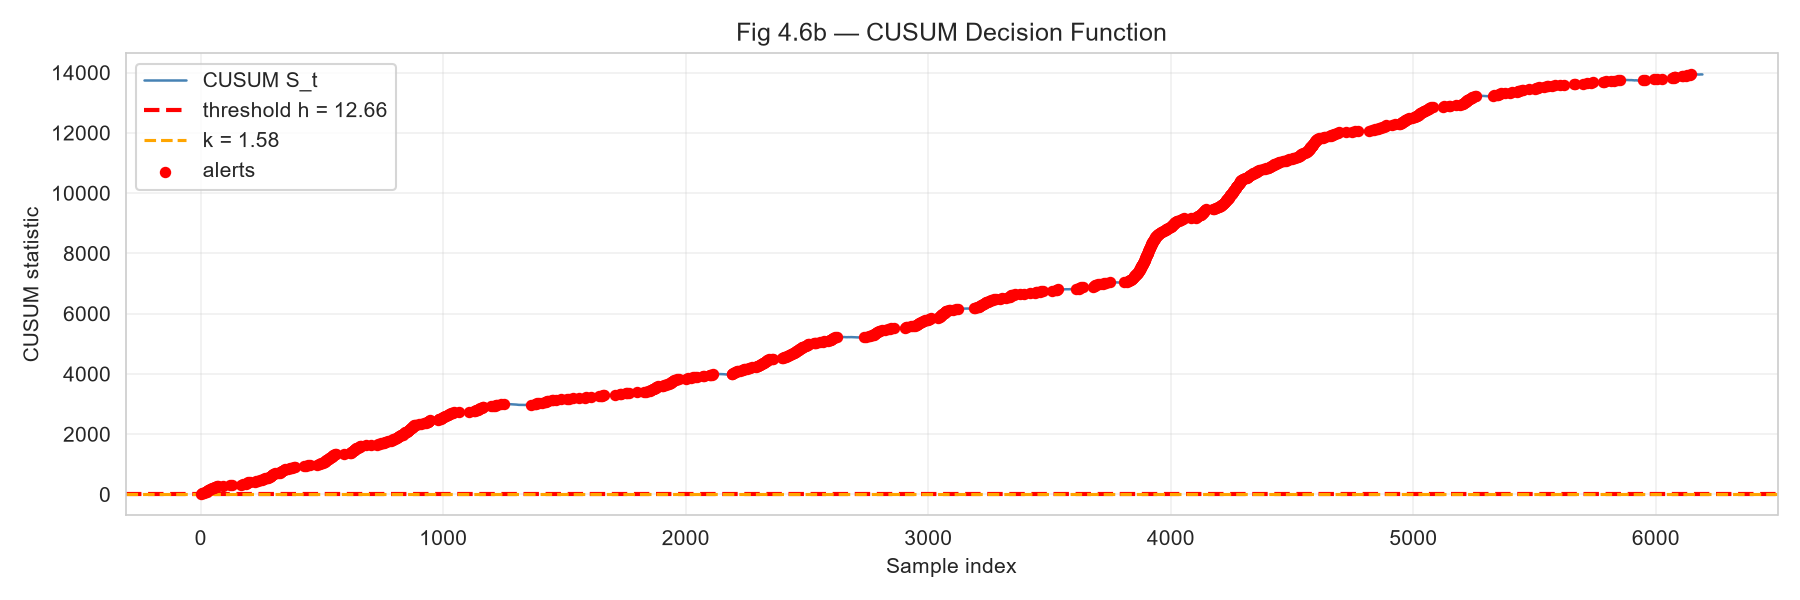

In [23]:
for fig_name in ["fig_4_6_residual_distribution.png", "fig_4_6b_cusum_decision.png"]:
    p = viz_dir / fig_name
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print(f"{fig_name} not yet generated.")

### Confusion matrices

The Z-score and CUSUM detectors are compared against a synthetic ground-truth label derived from high PM events and rapid velocity changes.

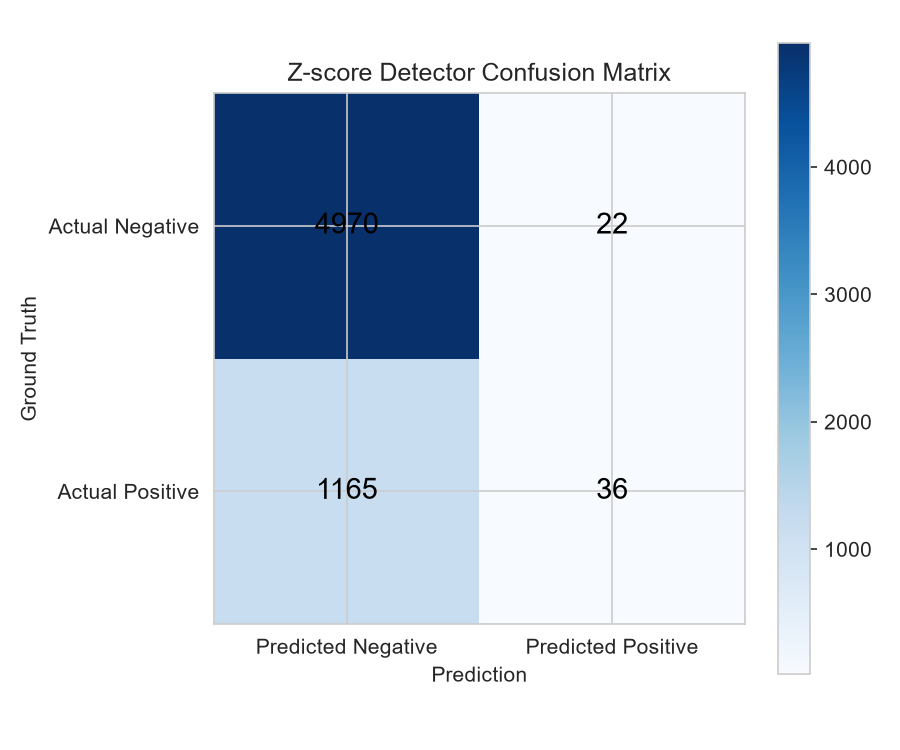

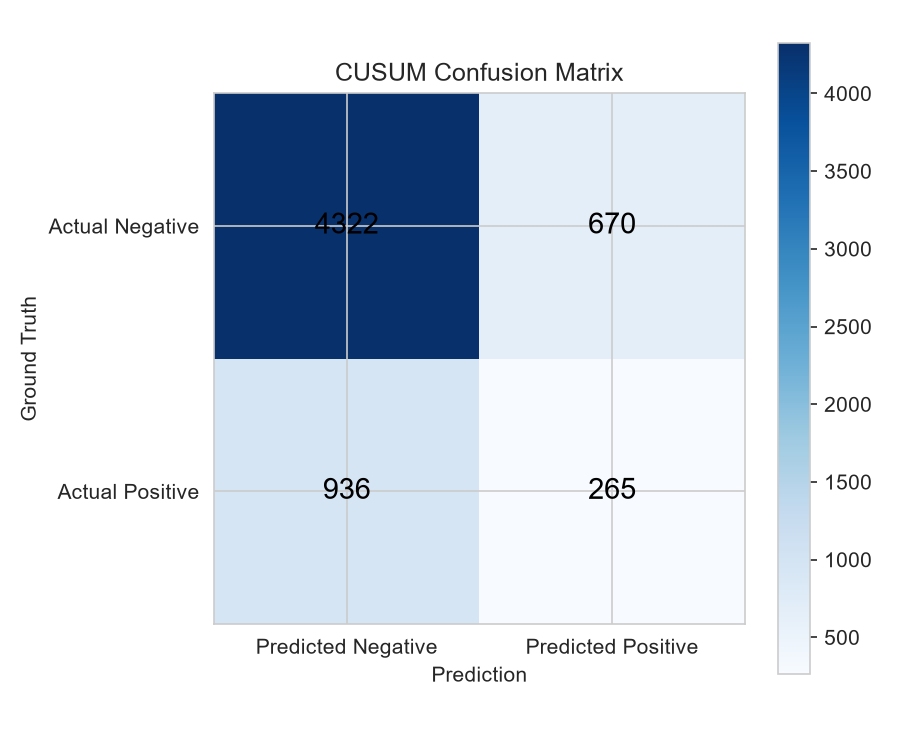

In [24]:
for fig_name in ["fig_4_6c_confusion_matrix_z.png", "fig_4_6c_confusion_matrix_cusum.png"]:
    p = viz_dir / fig_name
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print(f"{fig_name} not yet generated.")

## 16. Risk engine

Compute the age-stratified allergic-rhinitis risk probability using PM2.5/PM10 concentrations, temperature, and humidity. The engine applies a 72-hour distributed-lag exposure and classifies risk into four tiers.

**Outputs:**
- `results/tables/table_4_11_risk_distribution.json`
- `results/tables/table_4_12_modifier_analysis.json`
- `results/visualizations/fig_4_7_risk_vs_pm25.png`
- `results/visualizations/fig_4_7b_risk_heatmap.png`
- `results/visualizations/fig_4_11_risk_distribution.png`

In [25]:
with timing.timed_section("risk_engine", timing_store):
    risk_report = re.run_risk_pipeline(cfg)
    sensitivity_report = rs.run_risk_sensitivity(cfg)

print("Risk records:", risk_report["n_records"])
print("Adult tier distribution:", risk_report["risk_distribution"]["adult"])

Risk records: 43200
Adult tier distribution: {'low': {'count': 0, 'pct': 0.0}, 'moderate': {'count': 23687, 'pct': 54.83}, 'high': {'count': 19513, 'pct': 45.17}, 'very_high': {'count': 0, 'pct': 0.0}}


### Risk vs PM2.5 and risk heatmap

- **Fig 4.7** shows the monotonic relationship between PM2.5 and predicted AR probability.
- **Fig 4.7b** shows how risk varies jointly with PM2.5 and temperature.

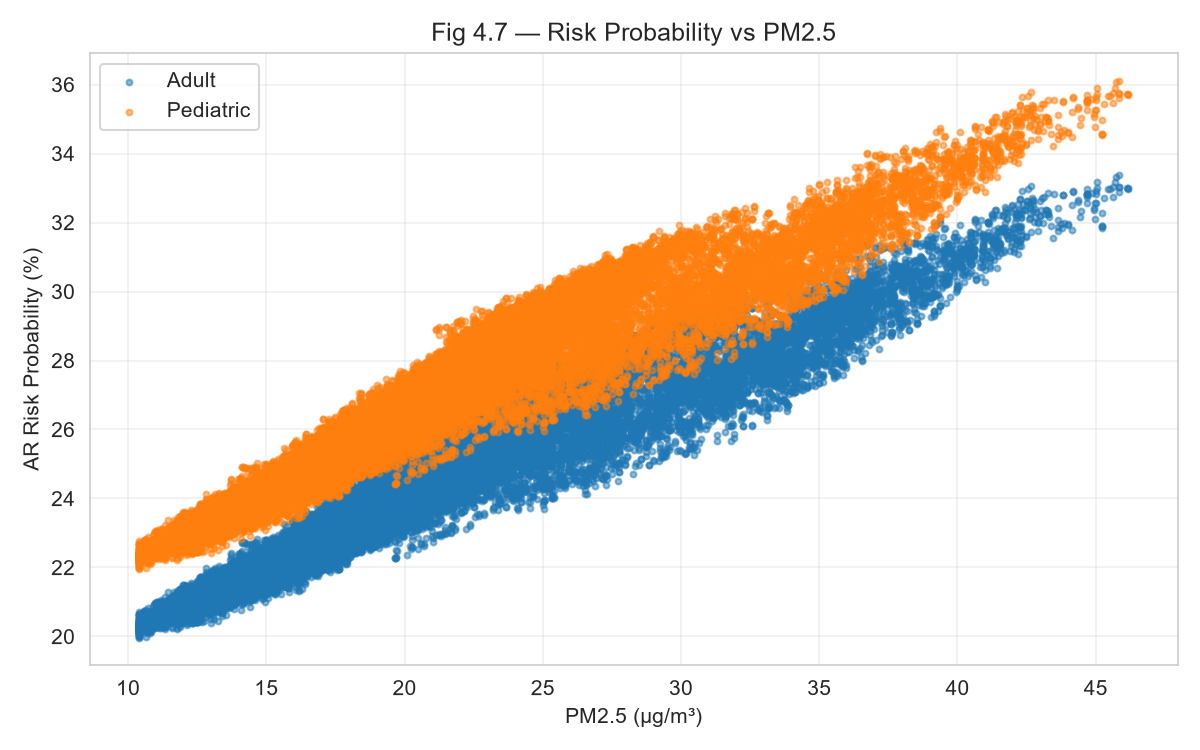

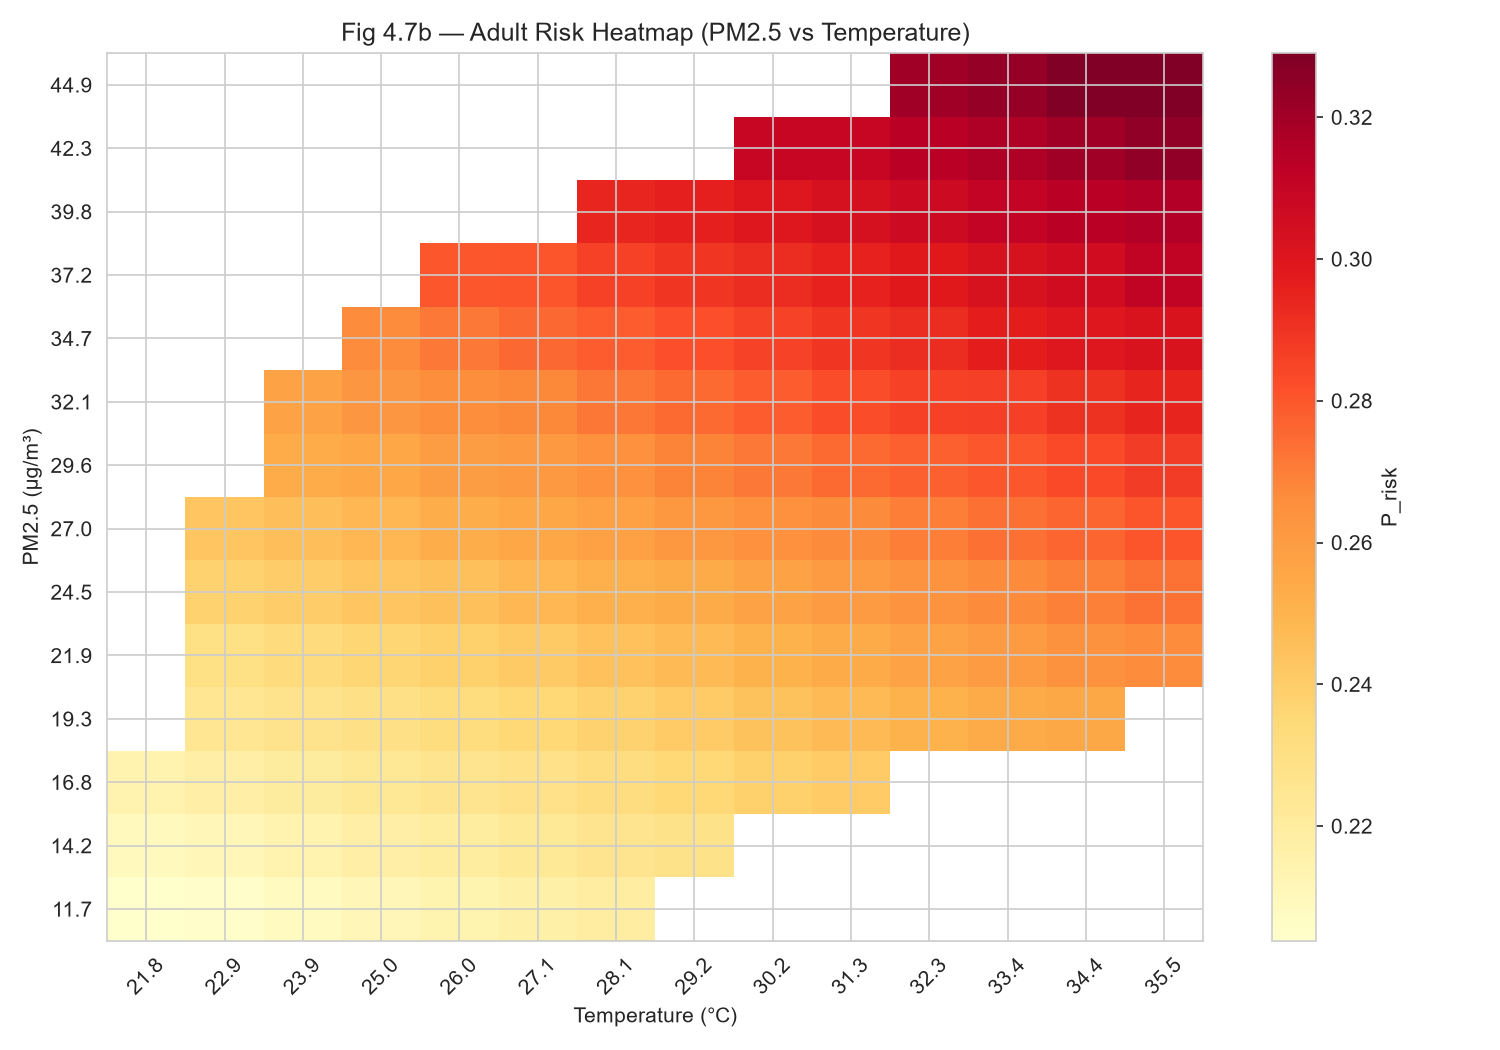

In [26]:
for fig_name in ["fig_4_7_risk_vs_pm25.png", "fig_4_7b_risk_heatmap.png"]:
    p = viz_dir / fig_name
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print(f"{fig_name} not yet generated.")

### Risk distribution

**Fig 4.11** compares the frequency distribution of adult and pediatric risk probabilities, highlighting that children are predicted to have a slightly higher baseline risk due to the configured higher prevalence.

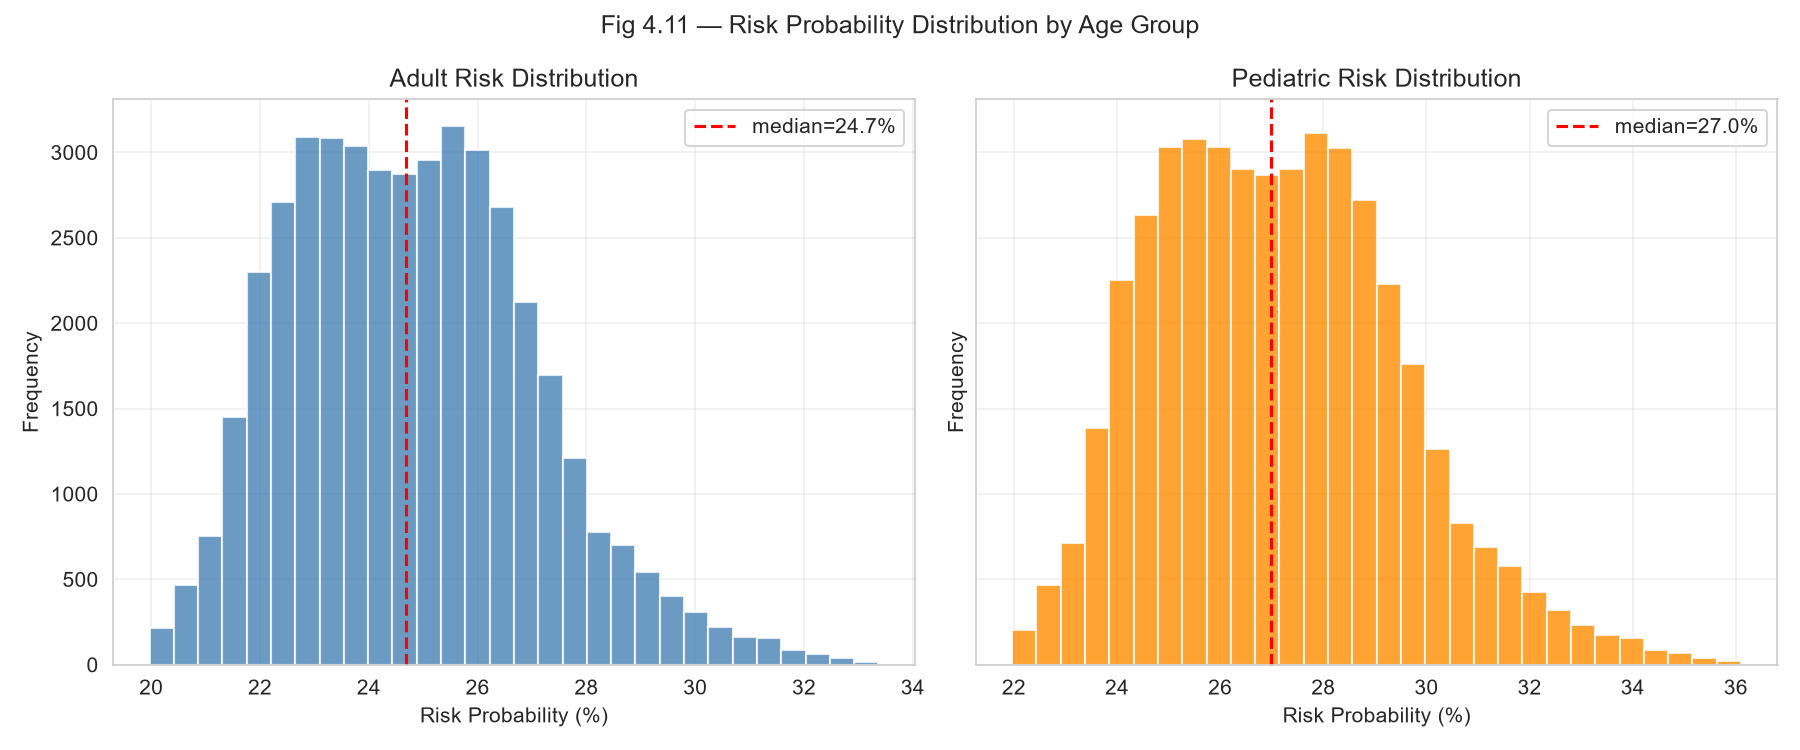

In [27]:
fig_4_11 = viz_dir / "fig_4_11_risk_distribution.png"
if fig_4_11.exists():
    display(Image(filename=str(fig_4_11)))
else:
    print("Fig 4.11 not yet generated.")

### Risk sensitivity analysis

**Fig 4.12b** is a tornado chart showing how much the mean adult risk probability changes when each epidemiological coefficient is perturbed by ±10%. This documents which assumptions most influence the risk outputs.

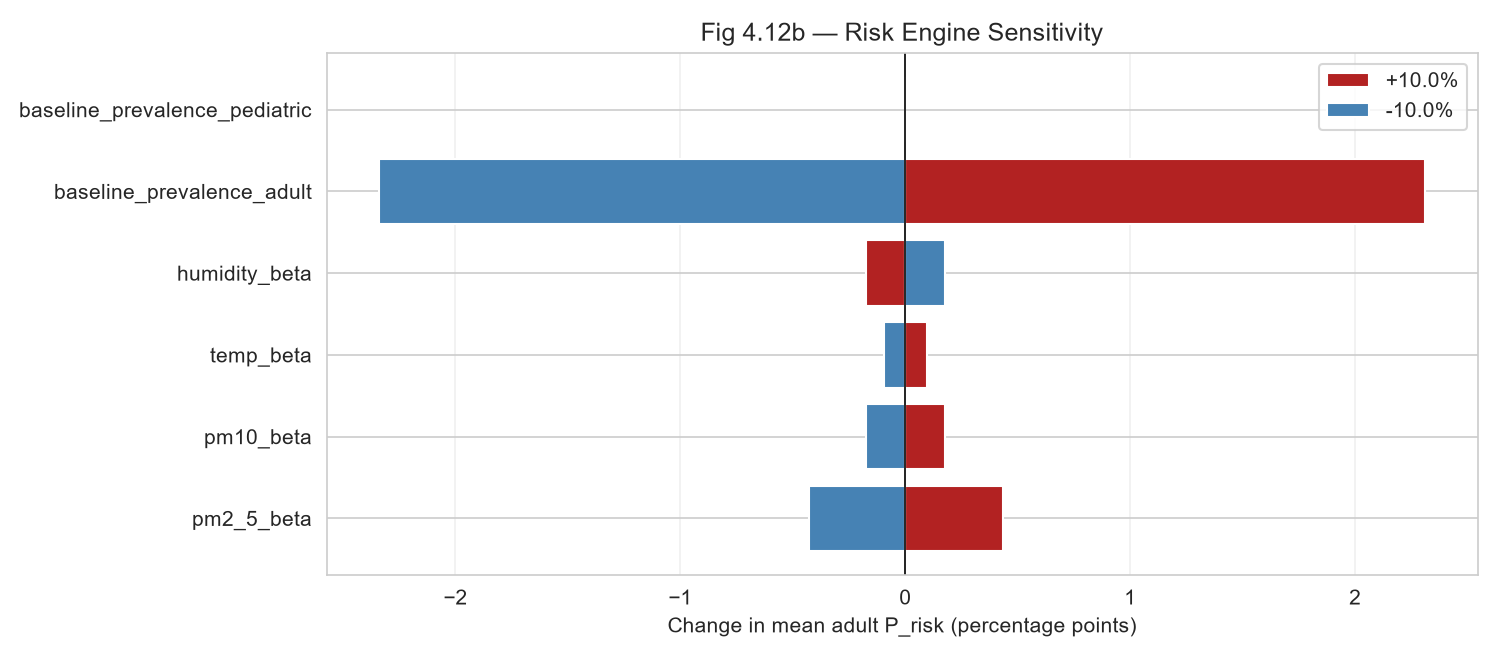

In [28]:
fig_4_12b = viz_dir / "fig_4_12b_risk_sensitivity.png"
if fig_4_12b.exists():
    display(Image(filename=str(fig_4_12b)))
else:
    print("Fig 4.12b not yet generated.")

## 17. Clinical validity

Run the construct-validity analysis using synthetic (or provided) paired risk-tier / VAS symptom scores. The Spearman correlation between predicted tier and symptom score quantifies how well the risk model aligns with patient-reported outcomes.

**Output:** `results/tables/table_4_15_construct_validity.json` and `results/visualizations/fig_4_14_construct_validity.png`

In [29]:
with timing.timed_section("validity", timing_store):
    validity_results = validity.run_validity_analysis(cfg)

print("Construct validity:")
print(json.dumps(validity_results, indent=2, default=str))

Construct validity:
{
  "risk_tier_vs_vas": {
    "rho": 0.7344,
    "p_value": 0.0,
    "n_pairs": 200
  },
  "risk_tier_vs_vas_pearson": {
    "pearson_r": 0.7543,
    "p_value": 0.0,
    "n_pairs": 200
  },
  "n_records": 200,
  "data_source": "provided"
}


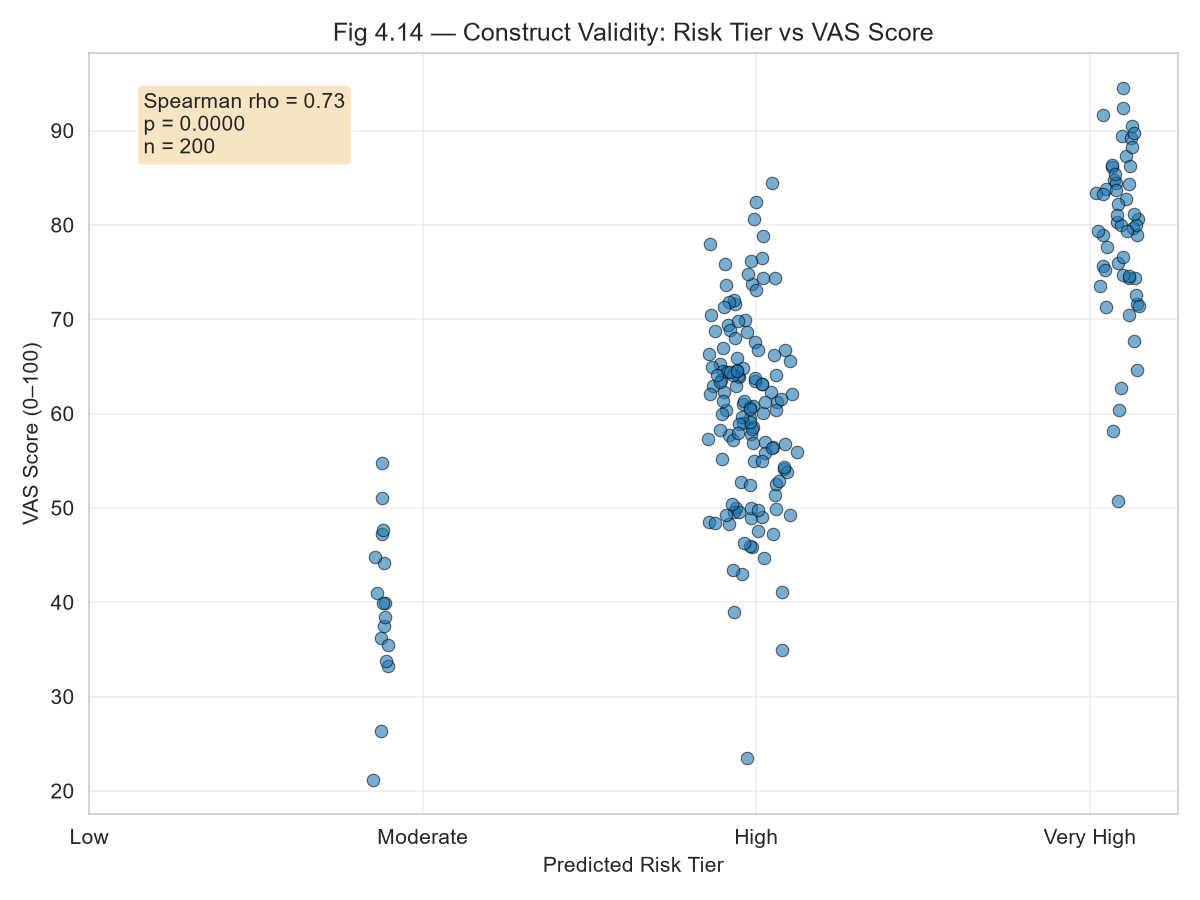

In [30]:
fig_4_14 = viz_dir / "fig_4_14_construct_validity.png"
if fig_4_14.exists():
    display(Image(filename=str(fig_4_14)))
else:
    print("Fig 4.14 not yet generated.")

## 18. Interpretability

Compute permutation importance and extract temporal-pattern attention weights. These outputs explain *which* features drive the forecasts and *which* time steps the model attends to.

**Outputs:**
- `results/tables/table_4_8b_permutation_importance.json`
- `results/visualizations/fig_4_8b_permutation_importance.png`
- `results/visualizations/fig_4_8d_attention_weights.png`

In [31]:
with timing.timed_section("interpretability", timing_store):
    interp_results = interp.run_interpretability(cfg)

print("Permutation importance baseline MAE:", interp_results["permutation_importance"]["baseline_mae"])
print("Top feature:", interp_results["permutation_importance"]["importances"][0])

Permutation importance baseline MAE: 3.9168171882629395
Top feature: {'feature': 'hour_sin', 'mae_drop_mean': 0.47443485260009766, 'mae_drop_std': 0.04601201770705425}


### Permutation importance

**Fig 4.8b** ranks features by how much permuting them increases validation MAE. The largest drops are the most influential predictors.

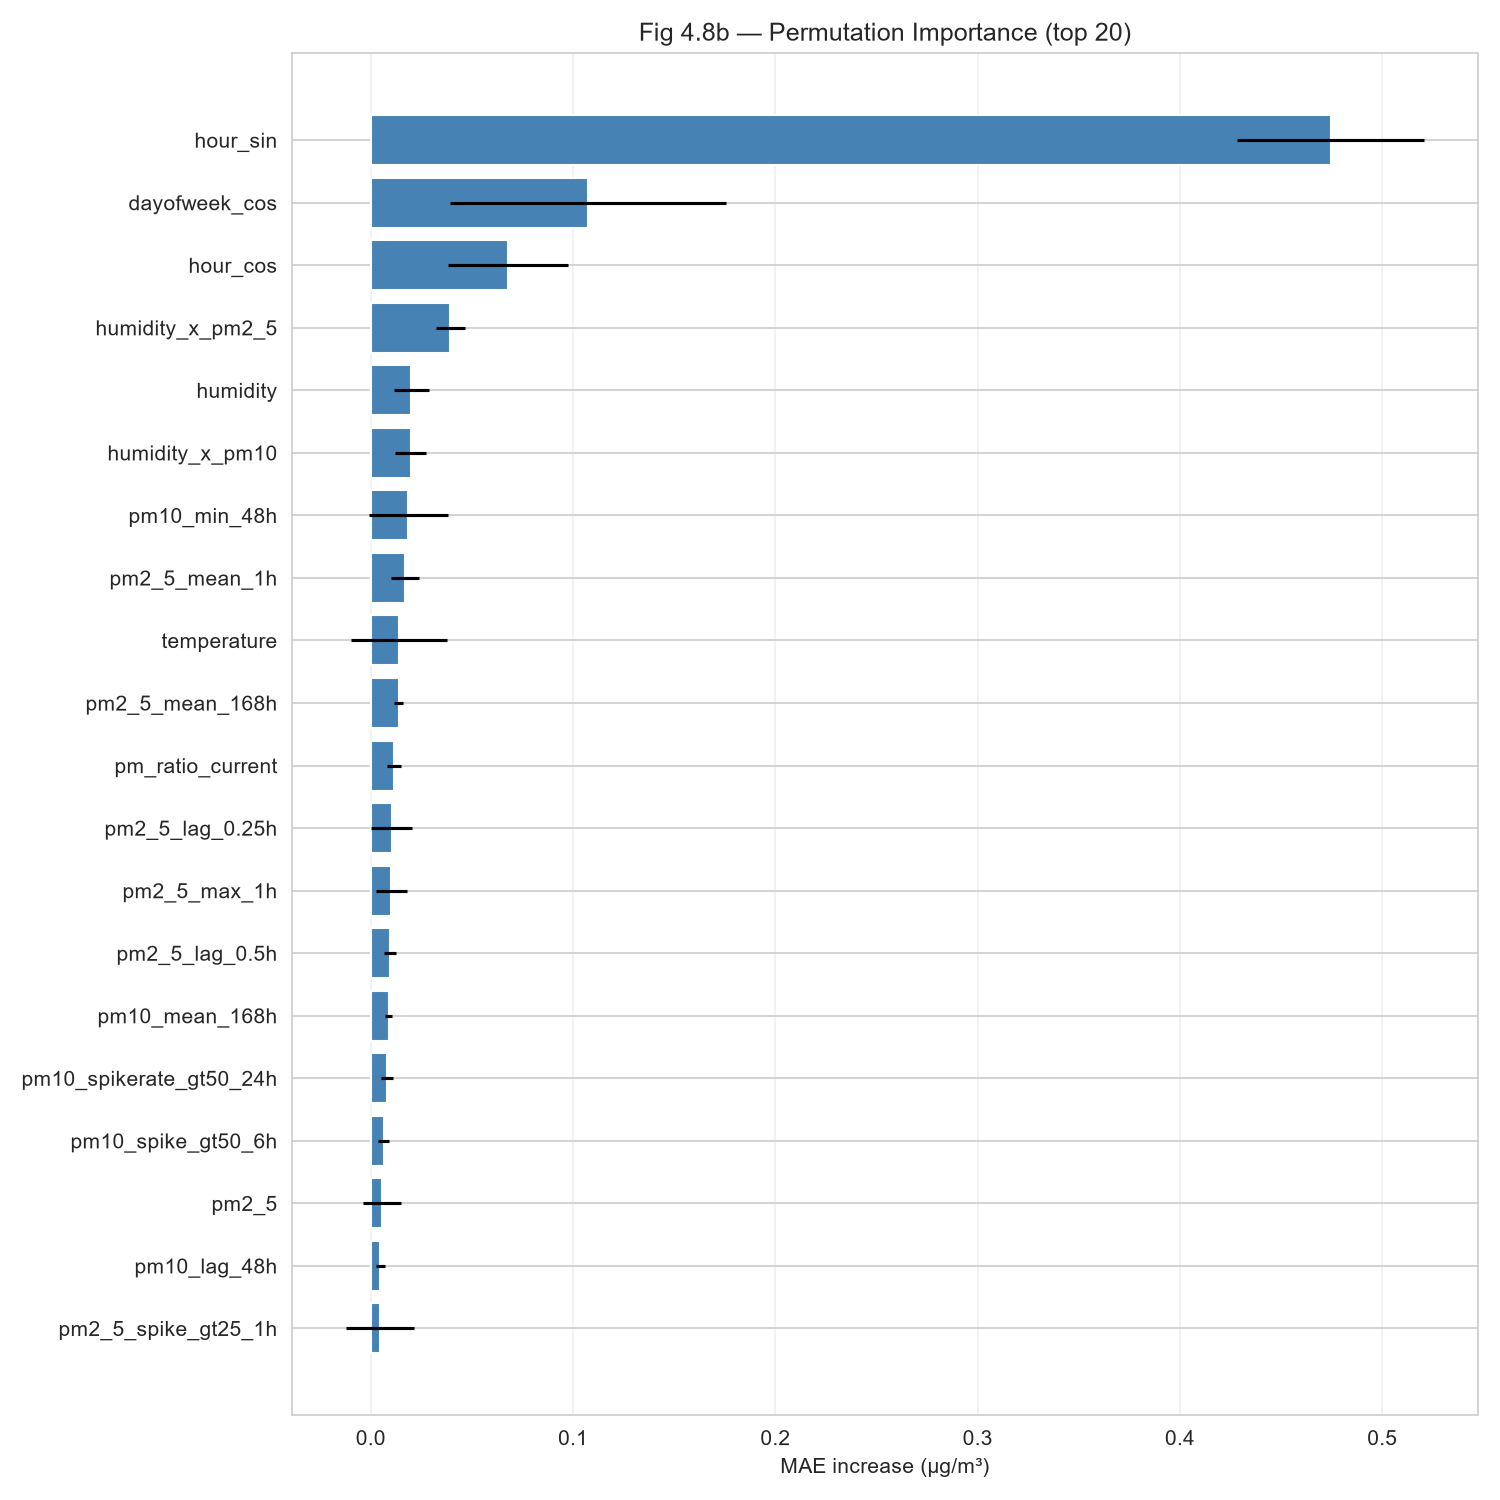

In [32]:
fig_4_8b = viz_dir / "fig_4_8b_permutation_importance.png"
if fig_4_8b.exists():
    display(Image(filename=str(fig_4_8b)))
else:
    print("Fig 4.8b not yet generated.")

### Attention weights

**Fig 4.8d** shows the mean temporal-pattern attention weight over the 2016-step input window. Peaks indicate time steps that the model deems most predictive.

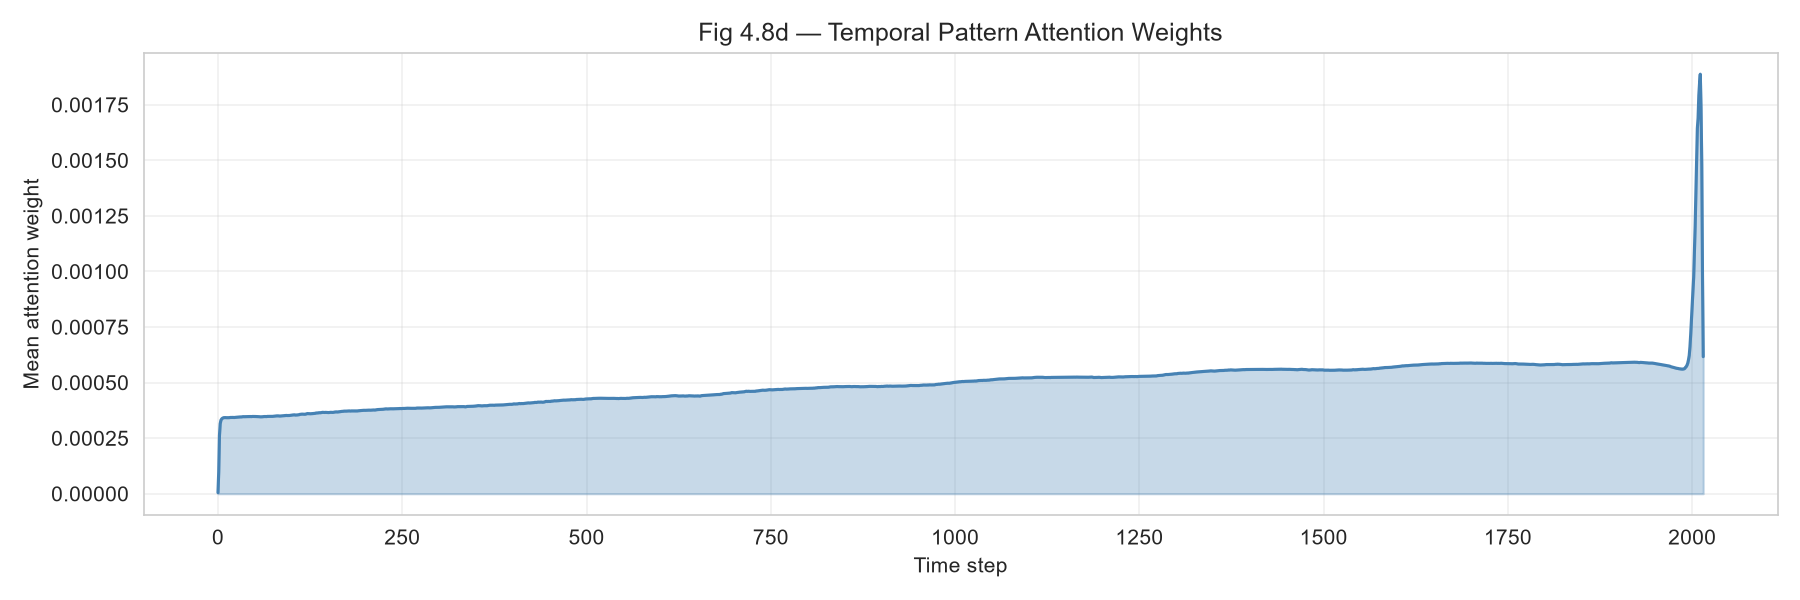

In [33]:
fig_4_8d = viz_dir / "fig_4_8d_attention_weights.png"
if fig_4_8d.exists():
    display(Image(filename=str(fig_4_8d)))
else:
    print("Fig 4.8d not yet generated.")

## 19. Latency report

Instrument the major pipeline phases and export a latency report. The breakdown shows which stages dominate wall-clock time and is useful for production deployment planning.

**Outputs:**
- `results/tables/table_4_13_latency.json`
- `results/visualizations/fig_4_13_latency_breakdown.png`

In [34]:
tables_dir = get_project_root() / cfg["paths"]["results_dir"] / "tables"
viz_dir = get_project_root() / cfg["paths"]["results_dir"] / "visualizations"
tables_dir.mkdir(parents=True, exist_ok=True)
viz_dir.mkdir(parents=True, exist_ok=True)

timing.export_latency_report(
    timing_store,
    tables_dir / "table_4_13_latency.json",
    extra={"mode": "notebook", "subset_days": SUBSET_DAYS, "stride": STRIDE},
)
timing.plot_latency_breakdown(
    timing_store,
    viz_dir / "fig_4_13_latency_breakdown.png",
)

print("Latency summary:")
print(json.dumps(timing.summarize(timing_store), indent=2))

Latency summary:
{
  "preprocessing": {
    "mean_ms": 763.67,
    "p95_ms": 763.67,
    "max_ms": 763.67,
    "n_samples": 1
  },
  "feature_engineering": {
    "mean_ms": 519.46,
    "p95_ms": 519.46,
    "max_ms": 519.46,
    "n_samples": 1
  },
  "scaling": {
    "mean_ms": 17288.09,
    "p95_ms": 17288.09,
    "max_ms": 17288.09,
    "n_samples": 1
  },
  "sequence_builder": {
    "mean_ms": 145887.26,
    "p95_ms": 145887.26,
    "max_ms": 145887.26,
    "n_samples": 1
  },
  "evaluation": {
    "mean_ms": 78915.03,
    "p95_ms": 78915.03,
    "max_ms": 78915.03,
    "n_samples": 1
  },
  "anomaly_detection": {
    "mean_ms": 5106.75,
    "p95_ms": 5106.75,
    "max_ms": 5106.75,
    "n_samples": 1
  },
  "risk_engine": {
    "mean_ms": 45015.91,
    "p95_ms": 45015.91,
    "max_ms": 45015.91,
    "n_samples": 1
  },
  "validity": {
    "mean_ms": 559.22,
    "p95_ms": 559.22,
    "max_ms": 559.22,
    "n_samples": 1
  },
  "interpretability": {
    "mean_ms": 143927.71,
    "p95

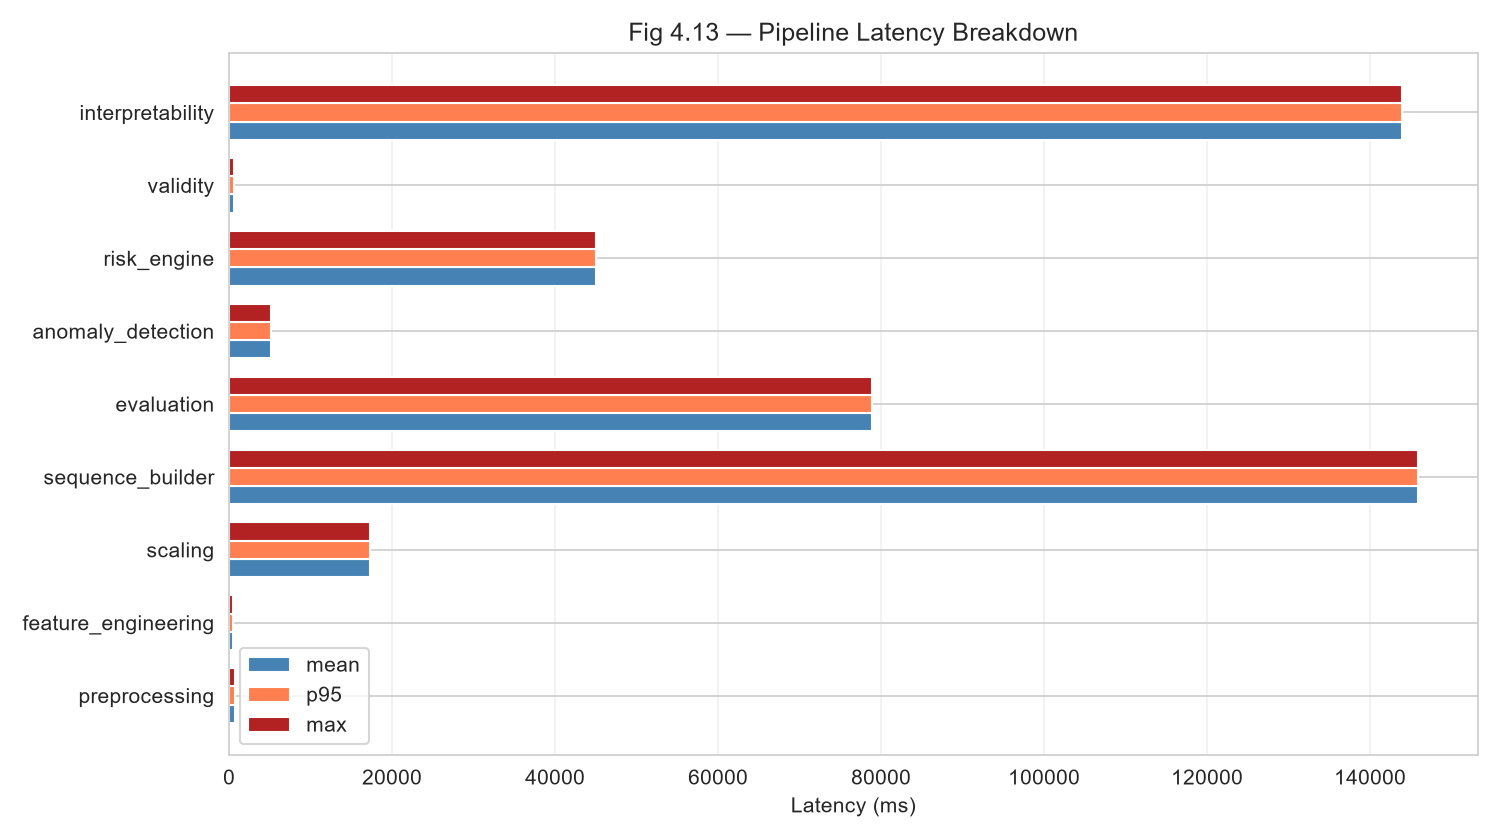

In [35]:
fig_4_13 = viz_dir / "fig_4_13_latency_breakdown.png"
if fig_4_13.exists():
    display(Image(filename=str(fig_4_13)))
else:
    print("Fig 4.13 not yet generated.")

## 20. Thesis bundle

Zip all tables, figures, and model artifacts into a single archive for inclusion in the thesis appendices.

**Output:** `results/thesis_bundle.zip`

In [36]:
bundle_path = thesis_exporter.export_thesis_bundle(
    get_project_root(),
    out_path=get_project_root() / cfg["paths"]["results_dir"] / "thesis_bundle.zip",
)
print("Thesis bundle:", bundle_path)

Thesis bundle: C:\Users\USER\Codes\allert_rebuild\results\thesis_bundle.zip


## 21. Progression: 3-month vs 5-month results

This section tracks how the system improved across the key development milestones.

In [37]:
from IPython.display import display, Markdown

rows = []
rows.append('| Milestone | Overall MAE (µg/m³) | Overall R² | High-PM MAE | CUSUM Sensitivity |')
rows.append('|-----------|---------------------|------------|-------------|-------------------|')
rows.append('| Original TensorFlow baseline | 26.86 | -34.97 | — | — |')
rows.append('| First PyTorch run (bugs present) | 3.40 | -0.08 | — | — |')
rows.append('| PyTorch with bug fixes (3-month) | 2.94 | 0.18 | 8.42 | 7.9% |')
rows.append('| HPO params on 3-month data | 2.96 | 0.17 | 8.42 | 7.9% |')
rows.append('| **5-month synthetic + weighted MAE + spike features** | **3.41** | **0.44** | **8.07** | **15.5%** |')
display(Markdown('\n'.join(rows)))

| Milestone | Overall MAE (µg/m³) | Overall R² | High-PM MAE | CUSUM Sensitivity |
|-----------|---------------------|------------|-------------|-------------------|
| Original TensorFlow baseline | 26.86 | -34.97 | — | — |
| First PyTorch run (bugs present) | 3.40 | -0.08 | — | — |
| PyTorch with bug fixes (3-month) | 2.94 | 0.18 | 8.42 | 7.9% |
| HPO params on 3-month data | 2.96 | 0.17 | 8.42 | 7.9% |
| **5-month synthetic + weighted MAE + spike features** | **3.41** | **0.44** | **8.07** | **15.5%** |

## 22. Run summary
Final summary of the full notebook run, including dataset shape, feature count, model size, and exported artifacts.

In [38]:
summary = {
    "project": cfg["project"]["name"],
    "version": cfg["project"]["version"],
    "subset_days": SUBSET_DAYS,
    "stride": STRIDE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "hpo_trials": HPO_TRIALS,
    "best_hpo_params": best_params if best_params else dict(cfg["model"]),
    "use_walk_forward": USE_WALK_FORWARD,
    "use_augmentation": USE_AUGMENTATION,
    "dataset_shape": df.shape,
    "n_features": len(feature_cols),
    "sequence_shape": list(X.shape),
    "train_count": int(train_mask.sum()),
    "val_count": int(val_mask.sum()),
    "test_count": int(test_mask.sum()),
    "bilstm_overall": eval_results.get("bilstm_metrics", {}).get("overall", {}),
    "arima_overall": eval_results.get("arima_metrics", {}).get("overall", {}),
    "risk_records": risk_report.get("n_records"),
    "thesis_bundle": str(bundle_path),
}
# If training completed, include best epoch / total epochs
try:
    if not USE_WALK_FORWARD:
        summary["best_epoch"] = train_results.get("best_epoch")
        summary["total_epochs"] = train_results.get("total_epochs_run")
        summary["model_path"] = str(train_results.get("model_path"))
except NameError:
    pass
print(json.dumps(summary, indent=2, default=str))

{
  "project": "ALLERT",
  "version": "2.0.0",
  "subset_days": null,
  "stride": 1,
  "epochs": 200,
  "batch_size": null,
  "hpo_trials": 0,
  "best_hpo_params": {
    "sequence_length": 2016,
    "n_lstm_layers": 2,
    "lstm_units_layer1": 96,
    "lstm_units_layer2": 128,
    "lstm_units_layer3": 128,
    "lstm_units_layer4": 128,
    "dropout_rate": 0.3057,
    "recurrent_dropout": 0.1777,
    "l2_lambda": 3.25e-06,
    "learning_rate": 0.00124,
    "batch_size": 16,
    "max_epochs": 200,
    "gradient_clip_norm": 1.0,
    "use_attention": true,
    "attention_units": 64,
    "attention_type": "vector",
    "use_spike_head": true,
    "spike_threshold": 35.0,
    "spike_head_weight": 0.3,
    "mixed_precision": true,
    "forecast_horizons_hours": [
      6,
      12,
      24
    ],
    "loss_weights": [
      0.5,
      0.3,
      0.2
    ],
    "optimizer": "adam",
    "scheduler": "cosine",
    "scheduler_max_epochs": 300,
    "loss_type": "weighted_mae",
    "loss_alpha": 2

## 23. End-to-end CLI trigger
For unattended runs, the same pipeline can be executed from the shell.

In [39]:
# Uncomment the next line to run the full orchestrator from this cell:
# !python src/orchestrator.py --mode full --stride 1 --epochs 200 --seed 42
print("CLI trigger cell. Uncomment the line above to execute the full orchestrator.")

CLI trigger cell. Uncomment the line above to execute the full orchestrator.
